In [ ]:
!git clone --depth 1 --filter=blob:none --sparse https://github.com/cselmo/CNN-en-Skin-Dataset.git
%cd CNN-en-Skin-Dataset
!git sparse-checkout set data/Split_smol

fatal: destination path 'CNN-en-Skin-Dataset' already exists and is not an empty directory.
/content/CNN-en-Skin-Dataset
remote: Enumerating objects: 844, done.
remote: Counting objects: 100% (844/844), done.
remote: Compressing objects: 100% (844/844), done.
remote: Total 844 (delta 0), reused 844 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (844/844), 167.52 MiB | 39.04 MiB/s, done.
Updating files: 100% (878/878), done.


# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [ ]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.14.1+cpu


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [ ]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 12s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


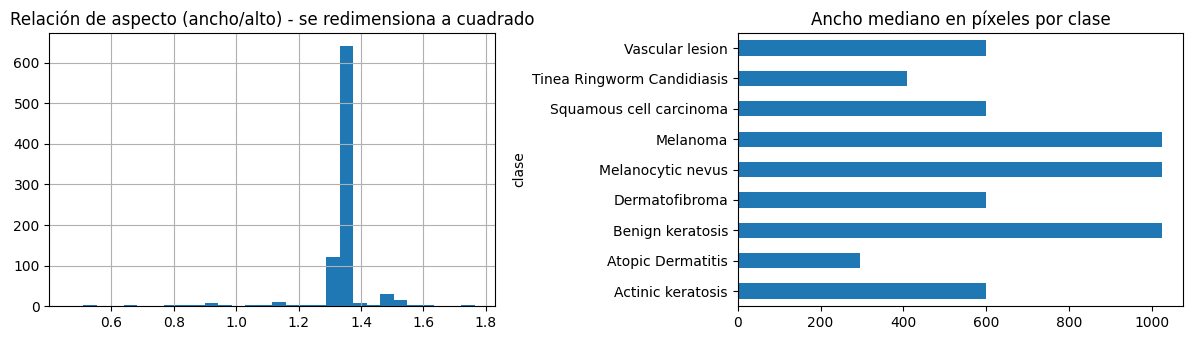

In [ ]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

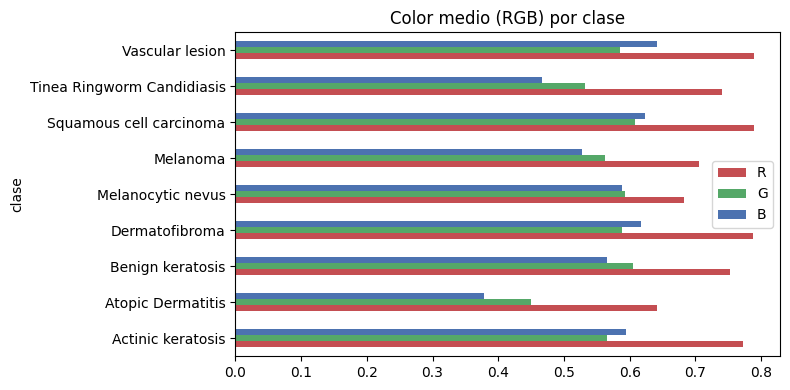

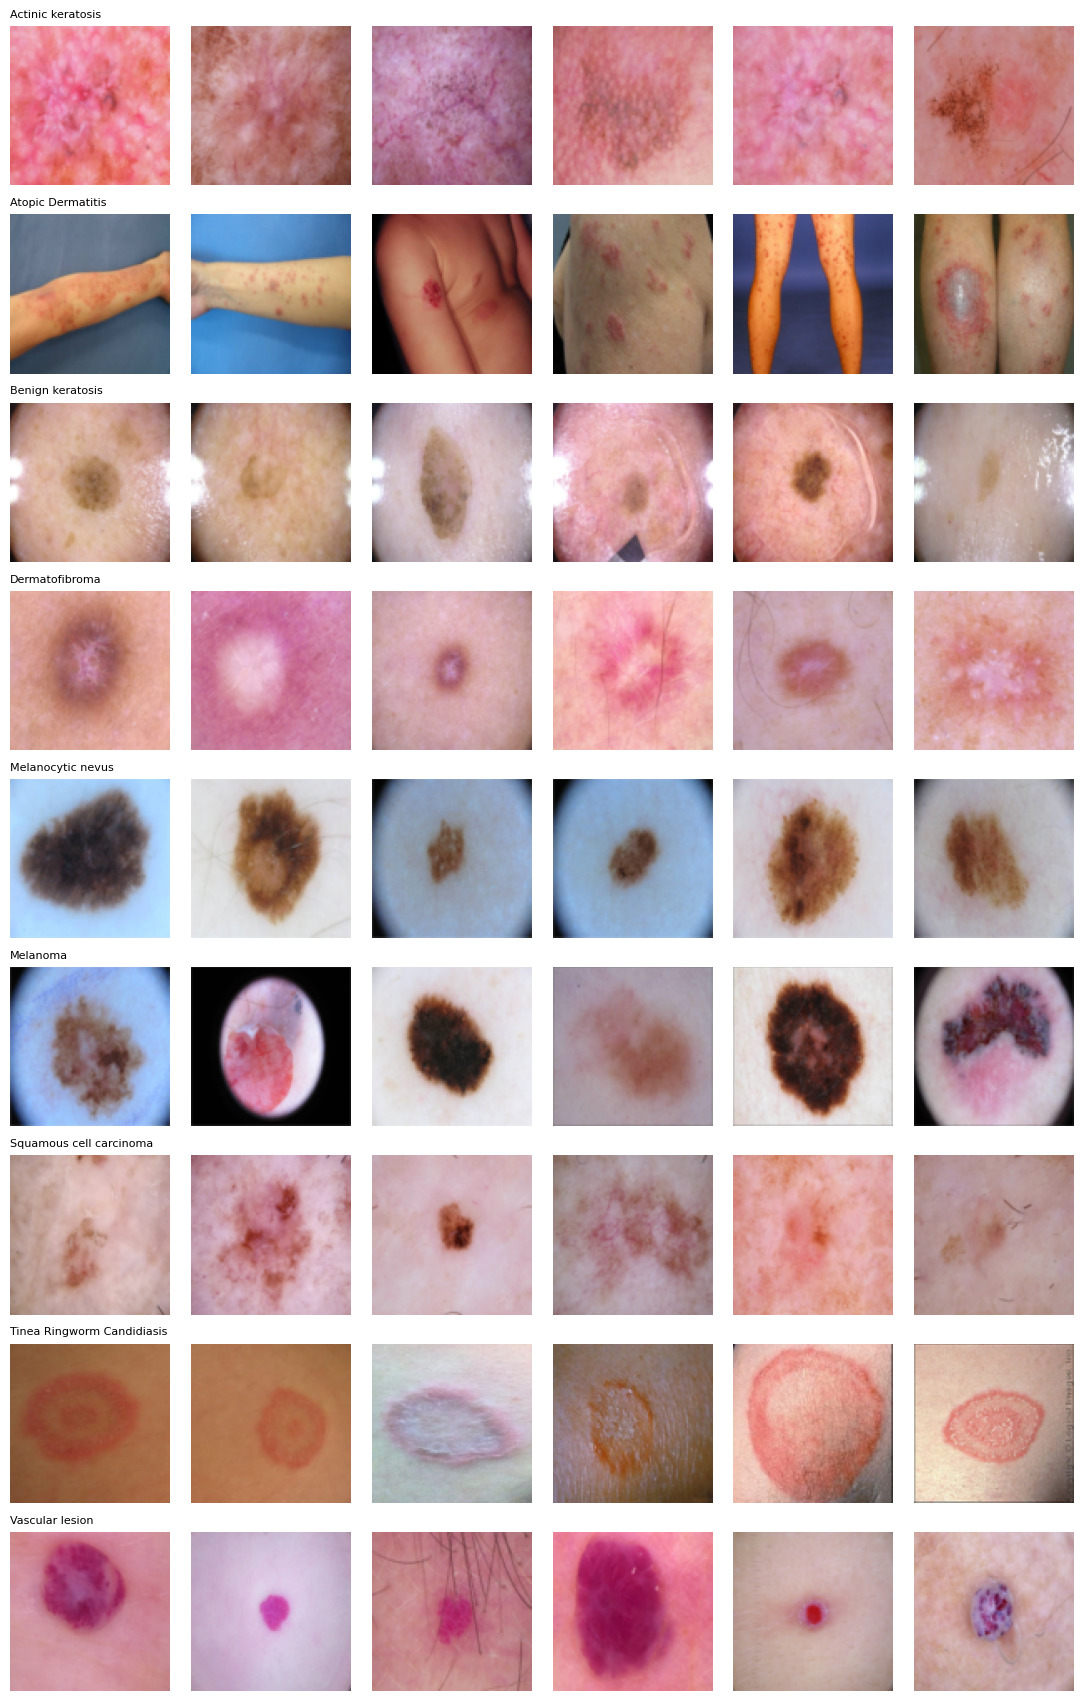

In [ ]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [ ]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
El dataset original no está tan desbalanceado. Todas las clases tienen la misma cantidad de imágenes (80 en train, 20 en val), excepto Atopic Dermatitis que cuenta con una imagen más en train y val (81 en train, 21 en val), y Tinea Ringworm Candidiasis, que cuenta con 24 imágenes menos en train (56 en train, 20 en val). La partición total es 697/181, pero hay un desbalance despreciable en Atopic Dermatitis, y uno considerable en Tinea Ringworm Candidiasis.
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
En cuanto a la resolución, se encuentran los dos casos: resoluciones para las cuales solo hay imágenes de una clase (ejemplo 1024x764 con Beningn Keratosis), y clases cuya totalidad de imágenes se encuentra en la misma resolución (ejemplo Atopic Dermatitis en 294x222). Sobre la relación de aspecto, el histograma que da el código es global, no se puede distinguir por clases (aunque podría haber una distinción marcada, la cual no se puede identificar con el histograma). El color medio muestra algunas clases más oscuras, con todos sus canales menores relativamente, como Atopic Dermatitis. El riesgo para el modelo es que se guíe por estas dsitinciones del datasetm propio, ya que no son realmente informativas sobre la clase, sino que sobre el dataset.
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?
Se encontraron 34 grupos de imágenes idénticas, de las cuales 33 estaban en train y en val. En Atopic Dermatitis se encontraron 22, y en Tinea Ringworm Candidiasis se encontraron 12. El valor final de la validación quedaría sobreestimado en caso de no eliminarse, ya que validaría el modelo con imágenes con las que fue entrenado.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [ ]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

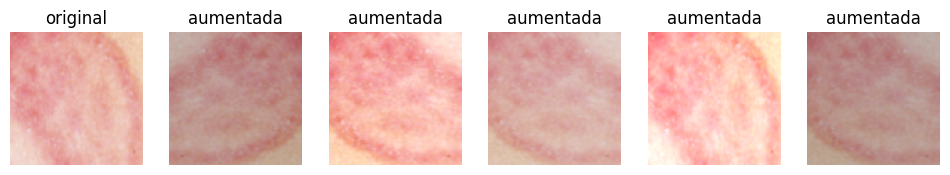

In [ ]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [ ]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [ ]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
En el primer caso, el kernel es de 3x3, por lo que el padding es de 1. El alto y el ancho de la imagen se mantienen a la salida de la convolución. Esto se puede ver en la tabla en las salidas de las capas 0, 4 y 8. Con padding = 0, se pierden dos píxeles de ancho y alto por convolución. Por ejemplo, la salida de las capa 0 sería de 62x62, la de la capa 4 de 29x29 (ya que el MaxPool2d lo llevaría a 31x31), para que la salida de la capa 11 sea de 6x6 (a diferencia del 8x8 de padding = 1).
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
Mantiene la cantidad de canales, pero reduce a la mitad tanto el alto como el ancho (se ve en las salidas de las capas 3, 7 y 11). Divide cada mapa en ventanas de 2x2, y toma el valor más alto de cada ventana. Se conserva la aparición de cada patrón y la intensidad, pero no el píxel específico entre los 4. La relación es que cada capa de MaxPool2d divide por 2 el lado de la entrada (entonces, el tamaño queda dividido por 2 la cantidad de veces igual a bloques haya).
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
Capa 4: un kernel de 3x3 tiene 9 pesos. La entrada tiene 16 canales: 9x16 = 144. Como hay 32 filtros, hay 32 kernels: 32x144 = 4608.
Capa 13: la entrada es de 4096. Cada entrada conecta con cada neurona de las 128: 4096x128 = 524288. Ademñas, se suma un bias a cada neurona: 524288 + 128 = 524416. La Linear domina el total (un 95% de los parámetros).
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
El mismo sesgo sería restado en la BatchNorm que sigue.
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
Ocurre porque MaxPool2d reduce a la mitad el alto y el ancho. Duplicar los canales compensa parte de esa pérdida: el volumen de activación se reduce a la mitad por bloque en lugar de a la cuarta parte. Además, las capas profundas combinan patrones más complejos y necesitan más canales, y como el mapa ya es más chico, el costo por bloque se mantiene parejo.
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.
r (campo receptivo), j (salto), k=3.
r=1, j=1, convolución ---- r=(3-1)x1+1=3, pool ----- r=3+1=4, j=2x1=2
r=4, j=2, convolución ---- r=(3-1)x2+4=8, pool ----- r=8+2=10, j=2x2=4
r=10, j=4, convolución ---- r=(3-1)x4+10=18
Para una imagen de 64 px, un parche de 18x18 representa el 8% del área de la imagen, que es lo que ve cada neurona de la última convolución.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 17 | val_acc 0.669 | train_acc 0.881 | 1.93 s/época | total 104s


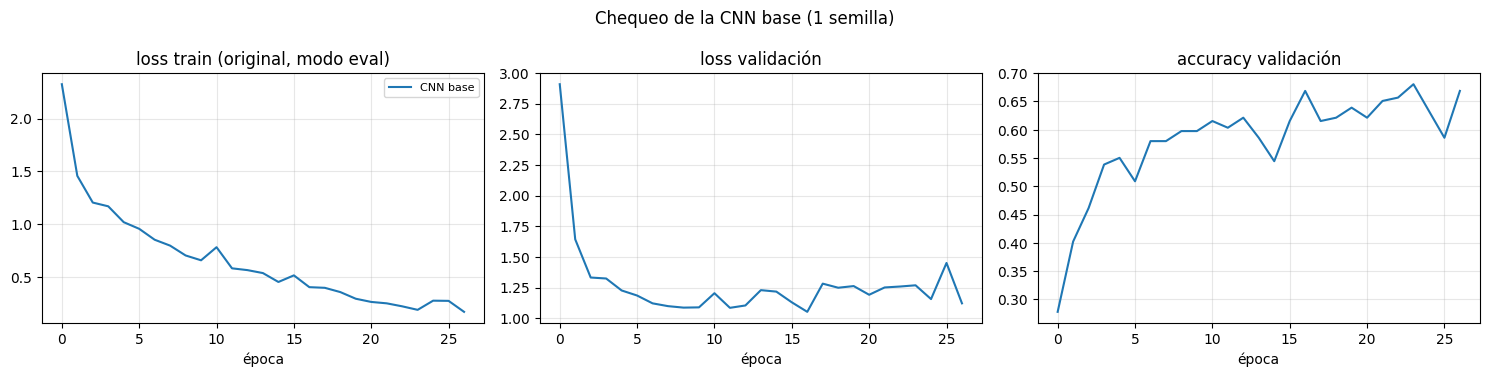

In [ ]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.2403,0.4346,0.0605
1,MLP 64px,6358793,0.5207,0.0531,0.7049,0.1842,7.0000,1.3036,0.4280,0.0927
2,CNN 32px,156057,0.6233,0.0201,0.8070,0.1837,8.0000,0.5276,0.5654,0.0579
3,CNN 64px,549273,0.6548,0.0155,0.8241,0.1693,13.3333,1.9204,0.5667,0.0881


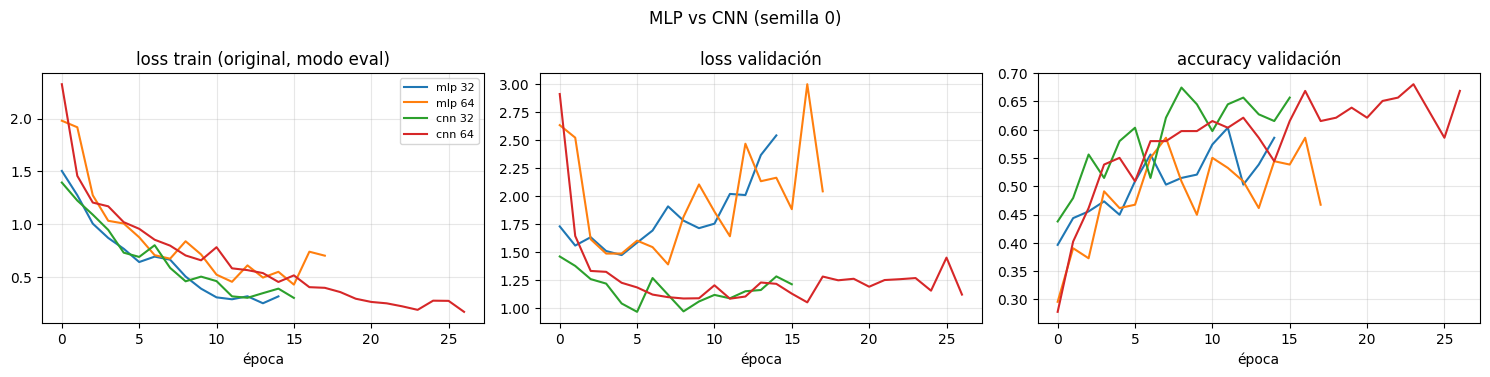

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [ ]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
Parámetros: MLP = 6358793, CNN = 549273.
Val_acc: MLP = 0.5207	(+-0.0531), CNN = 0.6548	(+-0.0155).
Brecha train-val: MLP = 0.1842, CNN = 0.1693.
Tiempo por época: MLP = 1.3036, CNN = 1.9204.
Época de convergencia: MLP = 7, CNN = 13,33.
La diferencia es de 0.1341, superando el ruido entre semillas y el error estándar.
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
32 px: Entradas=3x32x32, Pesos y bias: 3x32x32x512+512=1.573.376 parámetros.
64 px: Entradas=3x64x64, Pesos y bias: 3x64x64x512+512=6.291.968 parámetros.
224 px: Entradas=3x224x224, Pesos y bias: 3x224x224x512+512=77.070.848 parámetros.
La conectividad local y los pesos compartidos de la convolución mantendrían en todas las resoluciones la misma cantidad de parámetros: 432.
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
Se degrada menos CNN: 0,0881 contra 0,0927 de MLP a 64px. Sin embargo, la diferencia es muy pequeña en comparación al ruido.
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?
La normalización permite que las salidas de las capas quede dominada por la diferencia entre píxeles, y no su nivel medio (el cual pasa a ser 0). Se calculó restando a cada canal su media, y dividiendo por su desvío. En caso de no normalizar, el mismo learning rate sería desparejo para cada canal si difieren en media, y la convergencia sería más lenta.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6548,0.0155,0.8241,0.1693,13.3333,1.9101,44.6018
1,2 bloques,8,1055001,0.5897,0.0201,0.7339,0.1441,8.3333,1.5804,28.9400
2,4 bloques,38,361113,0.6686,0.0221,0.7978,0.1291,13.0000,2.2249,51.1570
3,kernel 5,32,591001,0.6114,0.0266,0.7958,0.1843,15.6667,2.7792,71.3453
4,kernel 7,46,653593,0.6174,0.0402,0.7918,0.1745,19.3333,3.9868,116.9056
5,8 filtros,18,269521,0.6509,0.0128,0.7734,0.1225,7.0000,0.8983,15.2673
6,32 filtros,18,1143337,0.5740,0.0128,0.7029,0.1289,10.3333,5.2286,106.3410
7,32 px,18,156057,0.6233,0.0201,0.8070,0.1837,8.0000,0.5370,9.6770
8,96 px,18,1204633,0.5582,0.0677,0.7220,0.1638,10.0000,5.0489,101.1315


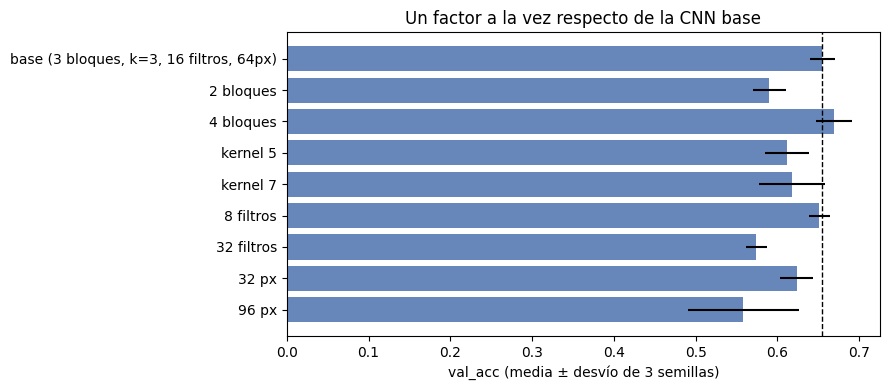

In [ ]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
Partiendo del val_acc de la base (0.6548+-0.0155), ningún factor cambia signficativamente la accuracy de val. La mejor es la de 4 bloques, con una diferencia de 0,0138, pero un ruido entre semillas de 0,022 (mayor que la diferencia).
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
Más bloques o kernels más grandes hacen que cada neurona vea una zona más grande de la imagen: 8 px con 2 bloques, 18 con 3, 38 con 4, y 32 y 46 px con kernel 5 y 7. Eso debería ayudar a ver la forma completa de la lesión, y no solo bordes y texturas. Con 2 bloques el modelo ve muy poco y empeora. Con 4 bloques mejora un poco y además tiene menos parámetros (361 k), aunque la mejora está dentro del ruido. Agrandar el kernel no mejoró y cuesta mucho más tiempo (71 y 117 s contra 45 s).
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
La Linear de la cabeza crece con el cuadrado del tamaño de la imagen: 131 k parámetros a 32 px, 524 k a 64 px y 1,18 M a 96 px. Más resolución da más detalle, pero también más cómputo (0,54 / 1,91 / 5,05 s por época), y cada neurona ve una parte más chica de la imagen. Con tan pocas imágenes, a 96 px el modelo se vuelve inestable.
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?
No se conocen las mejor combinaciones ni como interaccionan los factores. Además, 3 semillas no son suficientes para estimar bien el ruido para permitir al menos distinguir si cambiar un factor único mejor o no el modelo.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6548,0.0155,0.8241,0.1693,1.0672,13.3333,1.9452,45.3248
1,flips,1518,0.6331,0.0338,0.8116,0.1785,1.0574,8.6667,5.8434,109.2184
2,flips+rot90,1518,0.6391,0.0084,0.8011,0.1620,1.0646,8.6667,5.7804,108.0113
3,flips+rot90+color,1518,0.6213,0.0221,0.7747,0.1534,1.0392,8.6667,5.7788,107.8654


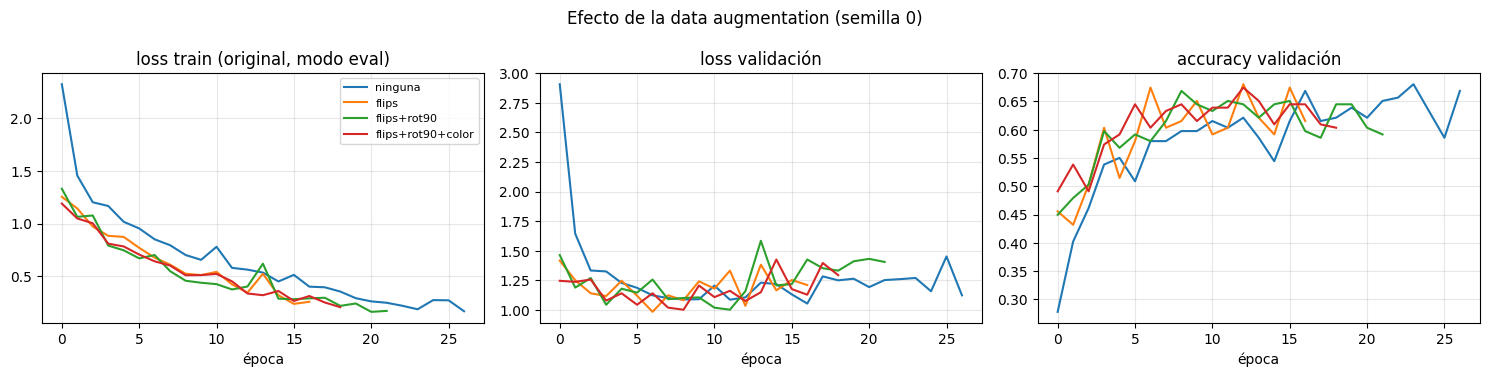

In [ ]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
La brecha train-val sin augmentation es de 0,1693, lo que indica un gran ajuste a los datos específicos de train. La val_loss empieza a subir, para la semilla 0, alrededor de la época 17.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
En flips, sube la brecha pero baja la val_loss. Disminuye la val_acc, baja la época de convergencia y el tiempo total sube. Con flips+rot90, baja la brecha y la val_loss. La val_acc disminuye, como también las épocas de convergencia, aunque sube el tiempo total. Con flips+rot90+color, la brecha, val_loss y val_acc disminuyen, y también las épocas de convergencia, pero sube el tiempo total. Cada época cuesta más porque aumenta el tamaño de train. Ninguna mejora supera el ruido enttre semillas.
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
Tienen sentido los flips y las rotaciones, porque una lesión no tiene orientación. El color puede destruir información, porque ayuda al diagnóstico: el melanoma tiene tonos oscuros y las lesiones vasculares, rojos. La escala también, porque un zoom puede cortar el borde de la lesión. Probaría rotaciones de cualquier ángulo, recortes chicos y augmentation nueva en cada época.
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
Porque si se aumenta antes del split, copias de una misma imagen pueden quedar en train y en val o test. El modelo ya las habría visto y las métricas saldrían infladas.
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?
Dropout y L2 limitan al modelo; la augmentation le agrega datos nuevos. En los dos casos la brecha baja un poco, pero la validación no mejora.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [ ]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): ninguna
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'ninguna'}
Config final en validación: val_acc 0.669 ± 0.022 | brecha 0.129 | mejor época 13.0 | 51s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6769,0.0250,0.6640,0.0242,49.5650
1,MLP 64px,6358793,0.5278,0.0298,0.5159,0.0246,20.0687


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.53      0.40      0.46        20
         Atopic Dermatitis       0.75      0.94      0.83        16
          Benign keratosis       0.86      0.90      0.88        20
            Dermatofibroma       0.52      0.85      0.64        20
         Melanocytic nevus       0.80      0.60      0.69        20
                  Melanoma       0.43      0.30      0.35        20
   Squamous cell carcinoma       0.45      0.45      0.45        20
Tinea Ringworm Candidiasis       0.67      0.62      0.64        13
           Vascular lesion       0.95      0.90      0.92        20

                  accuracy                           0.66       169
                 macro avg       0.66      0.66      0.65       169
              weighted avg       0.66      0.66      0.65       169



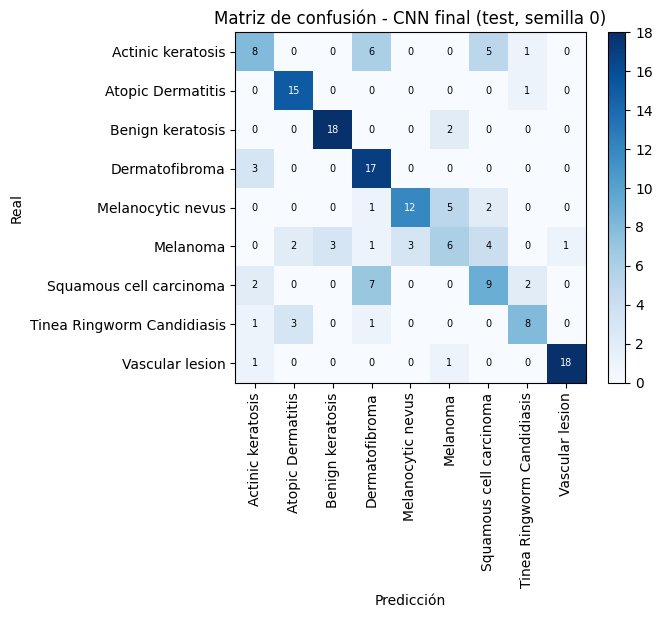

In [ ]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

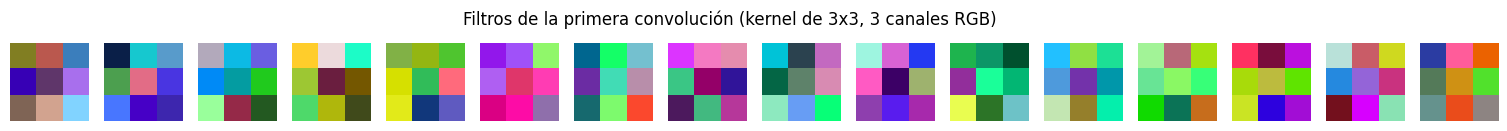

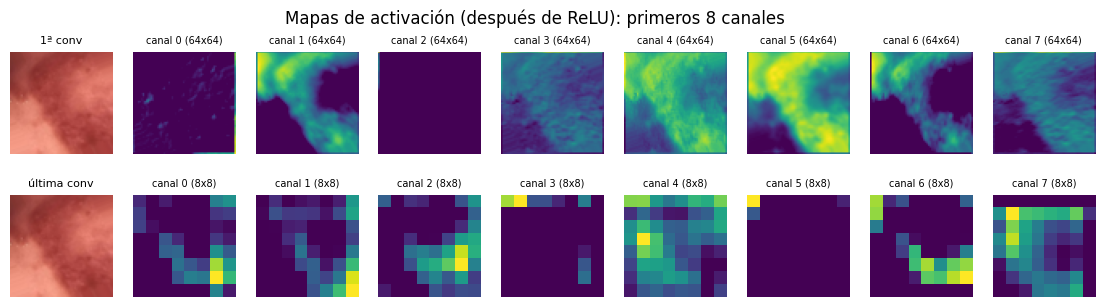

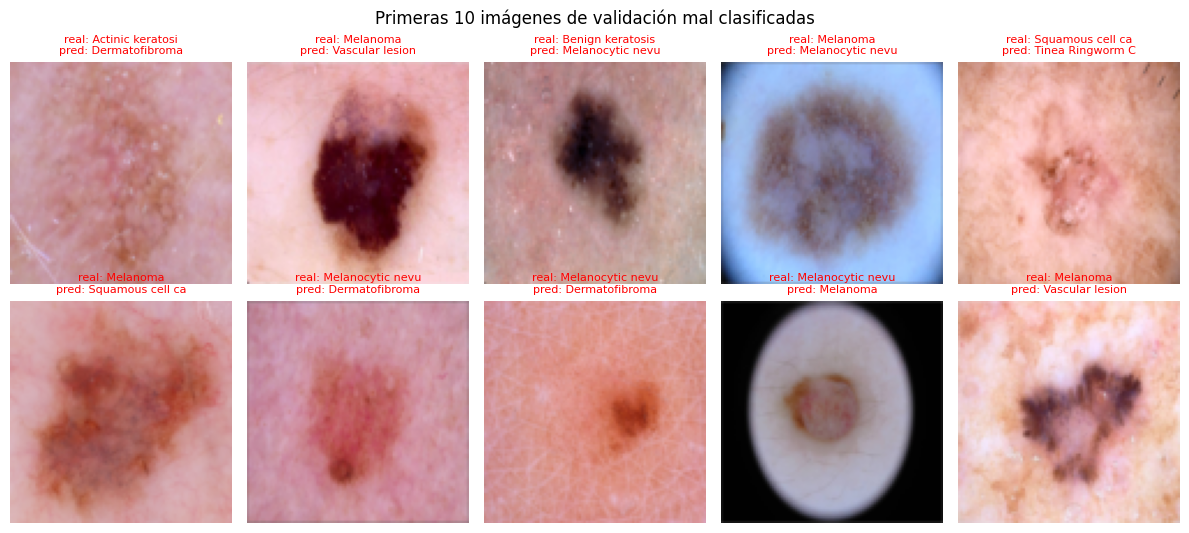

In [ ]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
Sí, son coherentes. En validación la configuración final dio 0,669 ± 0,022 y en test 0,6769 ± 0,025. La diferencia (0,008) es mucho menor que el error estándar del test (±0,036).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
La CNN supera a la MLP en test: 0,677 contra 0,528 de accuracy y 0,664 contra 0,516 de F1 macro. Los 15 puntos de diferencia superan con claridad tanto el desvío entre semillas (~0,03) como el error estándar (0,036). La CNN tiene 17,6 veces menos parámetros (361 k contra 6,36 M) y tarda 2,5 veces más en entrenar (50 contra 20 s). El costo se justifica.
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
Las clases que mejor se reconocen son vascular (F1 0,92), queratosis benigna (0,88) y atópica (0,83). La peor es el melanoma: recall de 0,30, solo 6 de 20. Se confunde con nevus, carcinoma escamoso y queratosis benigna, que son lesiones pigmentadas parecidas. Queratosis actínica y carcinoma escamoso se predicen seguido como dermatofibroma, porque las tres son lesiones rosadas de bajo contraste. No todos los errores son igual de graves: confundir un melanoma con un nevus es no detectar un cáncer. Por eso la métrica más relevante es el recall del melanoma (y de las clases malignas), junto con el F1 macro.
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
Los filtros de la primera capa detectan sobre todo colores y contrastes locales, y sus mapas de 64×64 todavía conservan la forma de la imagen. En la última capa los mapas son de 8×8, más dispersos y abstractos: cada celda resume una zona grande de la imagen. Entre las imágenes mal clasificadas predominan los melanomas, imágenes con el marco del dermatoscopio y lesiones rosadas de poco contraste.
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?
El EDA mostró que la resolución, el tipo de foto y el fondo dependen de la clase. Atópica y Tinea son fotos clínicas con fondos distintos al resto, así que el modelo puede usar el tipo de foto como atajo en lugar de mirar la lesión, y eso podría inflar resultados como el F1 de 0,83 de atópica. Los duplicados exactos se eliminaron, pero podría haber varias fotos del mismo paciente repartidas entre train y test. Además, el dataset es chico (844 imágenes), hay una sola partición, la validación y el test tienen solo 169 imágenes cada uno y el ruido se estimó con 3 semillas, así que varias diferencias no son concluyentes. Con más tiempo se podría usar validación cruzada y generar augmentation nueva en cada época.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

> Utilicé Claude para la descarga de los datos (generar el código inicial para tener la carpeta del repositorio). A su vez, confirmé mis respuestas numéricas (las que incluían cálculos, y las que requerían los datos de tabla, para evitar confusiones) y mejoré algunas de las redacciones.